<a href="https://colab.research.google.com/github/Angel-ag-1/ML-pipeline/blob/main/work/notebooks/capstone_By_Angel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [13]:
import os
import sys
import subprocess
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

REPO_URL = "https://github.com/Angel-ag-1/ML-pipeline.git"
REPO_DIR = "ML-pipeline"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                REPO_URL,
                REPO_DIR
            ],
            check=True
        )

    os.chdir(REPO_DIR)

print("Working directory:", os.getcwd())

Working directory: /content/ML-pipeline/ML-pipeline


In [14]:
!pip -q install pandas pyarrow huggingface_hub scikit-learn matplotlib

In [15]:
from huggingface_hub import (
    login,
    whoami,
    hf_hub_download
)

from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError(
        "HF_TOKEN was not found in Colab Secrets."
    )

login(token=HF_TOKEN)

print(
    "Hugging Face account:",
    whoami()["name"]
)

Hugging Face account: angelhi


In [16]:
march_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    repo_type="dataset",
    filename=(
        "fact_content_daily_performance/"
        "month=2026-03/data_0.parquet"
    )
)

march = pd.read_parquet(march_path)

print("March data shape:", march.shape)

March data shape: (9841378, 30)


In [17]:
march_agg = (
    march
    .groupby(
        [
            "client_hash_id",
            "content_hash_id"
        ]
    )
    .agg(
        gsc_impressions=(
            "gsc_impressions",
            "sum"
        ),
        gsc_clicks=(
            "gsc_clicks",
            "sum"
        ),
        gsc_avg_position=(
            "gsc_avg_position",
            "mean"
        ),
        ga4_sessions=(
            "ga4_sessions",
            "sum"
        ),
        ga4_pageviews=(
            "ga4_pageviews",
            "sum"
        )
    )
    .reset_index()
)

march_agg["ctr"] = (
    march_agg["gsc_clicks"]
    /
    march_agg["gsc_impressions"].replace(
        0,
        pd.NA
    )
)

march_agg["ctr"] = (
    march_agg["ctr"].fillna(0)
)

print("Webpages:", len(march_agg))
print(
    "Clients:",
    march_agg["client_hash_id"].nunique()
)

march_agg.head()

Webpages: 331437
Clients: 55


/tmp/ipykernel_17694/3157809512.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  march_agg["ctr"].fillna(0)


,client_hash_id,content_hash_id,gsc_impressions,gsc_clicks,gsc_avg_position,ga4_sessions,ga4_pageviews,ctr
0,client_0797ff3a1fc9a6a5,content_004e9c4c32e88631,0,0,NaN,0.0,0.0,0.0
1,client_0797ff3a1fc9a6a5,content_0236ef736698e17c,0,0,NaN,0.0,0.0,0.0
2,client_0797ff3a1fc9a6a5,content_025f6cfd3c298870,0,0,NaN,0.0,0.0,0.0
3,client_0797ff3a1fc9a6a5,content_0263d5f9b7a2ecd4,1,0,9.0,0.0,0.0,0.0
4,client_0797ff3a1fc9a6a5,content_02752c6c1c60161f,0,0,NaN,0.0,0.0,0.0


## 1. Question

*The research question and the decision it supports.*

This project investigates whether March 2026 search and website performance signals can help prioritise webpages for manual content review.

The decision supported is which webpages should be reviewed first. The results are intended as decision-support, not as automatic content decisions.

In [18]:
print("=" * 70)
print("RESEARCH QUESTION")
print("=" * 70)

print(
    "Can March 2026 search and website performance signals help "
    "prioritise webpages for manual content review?"
)

print()
print("Decision supported:")
print(
    "Which webpages should be prioritised for human review?"
)

print()
print(
    "This project provides decision-support only."
)

RESEARCH QUESTION
Can March 2026 search and website performance signals help prioritise webpages for manual content review?

Decision supported:
Which webpages should be prioritised for human review?

This project provides decision-support only.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

The analysis uses the FlyRank ML Internship dataset and March 2026 daily content performance data.

The data is aggregated by client and webpage. Client names, webpage URLs and private queries are excluded from the analysis.

In [19]:
print("=" * 70)
print("DATA SUMMARY")
print("=" * 70)

print("Dataset: FlyRank ML Internship dataset")
print(
    "Table: fact_content_daily_performance"
)
print("Date window: March 2026")
print("Dataset release/version: not recorded in this notebook.")

print()
print("Rows:", len(march))
print("Aggregated webpages:", len(march_agg))
print(
    "Unique clients:",
    march_agg["client_hash_id"].nunique()
)

print()
print("Excluded:")
print("- Client names")
print("- Webpage URLs")
print("- Private search queries")

print()
print(
    "Public-safe identifiers were used where necessary."
)

DATA SUMMARY
Dataset: FlyRank ML Internship dataset
Table: fact_content_daily_performance
Date window: March 2026
Dataset release/version: not recorded in this notebook.

Rows: 9841378
Aggregated webpages: 331437
Unique clients: 55

Excluded:
- Client names
- Webpage URLs
- Private search queries

Public-safe identifiers were used where necessary.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

A Decision Tree was trained to identify pages with zero March 2026 impressions. The model was compared with the Week-4 rule-based baseline using a grouped train/test split by client.

In [20]:
print("=" * 70)
print("METHODOLOGY")
print("=" * 70)

model_features = [
    "gsc_clicks",
    "gsc_avg_position",
    "ga4_sessions",
    "ga4_pageviews"
]

print("Model: Decision Tree Classifier")

print()
print("Target:")
print("needs_attention = March 2026 impressions == 0")

print()
print("Features:")
for feature in model_features:
    print("-", feature)

print()
print("Baseline:")
print("Rule-based Week-4 prioritisation score")
print()
print("Baseline scoring:")
print("- Zero impressions: +3 points")
print("- Zero clicks: +2 points")
print("- Average position above 20 (or missing): +1 point")
print("- Score >= 3: flagged for attention")
print("- Zero impressions alone reaches 3, so the baseline contains the target definition")

print()
print("Validation:")
print("Grouped train/test split by client_hash_id")

print()
print("Leakage checks:")
print("- Known issue: missing position and zero clicks co-occur with the zero-impression target")
print("- gsc_impressions excluded from model features")
print("- content_hash_id excluded")
print("- client_hash_id used only for grouping")
print("- No future months used")

METHODOLOGY
Model: Decision Tree Classifier

Target:
needs_attention = March 2026 impressions == 0

Features:
- gsc_clicks
- gsc_avg_position
- ga4_sessions
- ga4_pageviews

Baseline:
Rule-based Week-4 prioritisation score

Baseline scoring:
- Zero impressions: +3 points
- Zero clicks: +2 points
- Average position above 20 (or missing): +1 point
- Score >= 3: flagged for attention
- Zero impressions alone reaches 3, so the baseline contains the target definition

Validation:
Grouped train/test split by client_hash_id

Leakage checks:
- Known issue: missing position and zero clicks co-occur with the zero-impression target
- gsc_impressions excluded from model features
- content_hash_id excluded
- client_hash_id used only for grouping
- No future months used


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

The Decision Tree and Week-4 baseline were evaluated using the same grouped test split.

Accuracy, ROC-AUC, precision and recall are reported. The comparison measures performance on this validation design and does not prove general performance outside the available data.

In [21]:
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score
)

march_agg["needs_attention"] = (
    march_agg["gsc_impressions"] == 0
).astype(int)

X = march_agg[model_features].copy()
y = march_agg["needs_attention"].copy()
groups = march_agg["client_hash_id"].copy()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

model_pred = model.predict(X_test)
model_prob = model.predict_proba(X_test)[:, 1]

model_accuracy = accuracy_score(y_test, model_pred)
model_precision = precision_score(
    y_test, model_pred, zero_division=0
)
model_recall = recall_score(
    y_test, model_pred, zero_division=0
)

model_auc = (
    roc_auc_score(y_test, model_prob)
    if y_test.nunique() > 1 else float("nan")
)

baseline_test = march_agg.iloc[test_idx].copy()

baseline_test["baseline_score"] = (
    (baseline_test["gsc_impressions"] == 0).astype(int) * 3
    + (baseline_test["gsc_clicks"] == 0).astype(int) * 2
    + (baseline_test["gsc_avg_position"].fillna(100) > 20).astype(int)
)

baseline_pred = (
    baseline_test["baseline_score"] >= 3
).astype(int)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(
    y_test, baseline_pred, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_pred, zero_division=0
)

baseline_auc = (
    roc_auc_score(y_test, baseline_test["baseline_score"])
    if y_test.nunique() > 1 else float("nan")
)

comparison = pd.DataFrame({
    "Method": ["W04 Baseline", "Decision Tree"],
    "Accuracy": [baseline_accuracy, model_accuracy],
    "ROC_AUC": [baseline_auc, model_auc],
    "Precision": [baseline_precision, model_precision],
    "Recall": [baseline_recall, model_recall]
})

print("=" * 70)
print("MODEL VS BASELINE RESULTS")
print("=" * 70)

print(comparison.to_string(index=False))


Training rows: 297082 | Testing rows: 34355
MODEL VS BASELINE RESULTS
       Method  Accuracy  ROC_AUC  Precision  Recall
 W04 Baseline  0.884646      1.0   0.785145     1.0
Decision Tree  1.000000      1.0   1.000000     1.0


## 5. Limitations

*What this work cannot claim.*
This project uses a limited March 2026 dataset and a proxy target based on zero impressions.

The model cannot determine content quality or the true cause of low visibility. Factors such as page age, indexing status, seasonality, and business value are not included.

In [22]:
print("=" * 70)
print("LIMITATIONS")
print("=" * 70)

limitations = [
    "Only March 2026 data is used.",
    "The target is a proxy based on zero impressions.",
    "The model cannot measure content quality directly.",
    "Page age is not included.",
    "Indexing status is not included.",
    "Seasonality is not included.",
    "Business value is not included.",
    "The model does not identify the true cause of low visibility."
]

for item in limitations:
    print("-", item)

no_pos = march_agg["gsc_avg_position"].isna()
zero_imp = march_agg["needs_attention"] == 1
print(f"Pages with missing position: {no_pos.sum():,}")
print(f"Pages with zero impressions: {zero_imp.sum():,}")
print(f"Overlap: {(no_pos & zero_imp).sum():,}")
print()
print("The target is defined from impressions, and the features (position, clicks)")
print("are empty or zero whenever impressions are zero. Scores here measure how well")
print("the model recovers the proxy, not how well it predicts future decline.")
print("The Week-4 baseline contains the target definition, so its score is not")
print("independent evidence.")

print()
print(
    "These results describe how well March signals recover the "
    "zero-impression proxy. They are not evidence of forecasting "
    "performance and should be treated as decision-support only."
)

LIMITATIONS
- Only March 2026 data is used.
- The target is a proxy based on zero impressions.
- The model cannot measure content quality directly.
- Page age is not included.
- Indexing status is not included.
- Seasonality is not included.
- Business value is not included.
- The model does not identify the true cause of low visibility.
Pages with missing position: 154,699
Pages with zero impressions: 154,699
Overlap: 154,699

The target is defined from impressions, and the features (position, clicks)
are empty or zero whenever impressions are zero. Scores here measure how well
the model recovers the proxy, not how well it predicts future decline.
The Week-4 baseline contains the target definition, so its score is not
independent evidence.

These results describe how well March signals recover the zero-impression proxy. They are not evidence of forecasting performance and should be treated as decision-support only.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The action playbook prioritises webpages for manual review using reason codes.

Pages with low visibility, no clicks or poor search position may be reviewed first. Human review is required before any content changes are made.

In [23]:
print("=" * 70)
print("RANKED RECOMMENDATIONS")
print("=" * 70)

queue = march_agg.copy()

queue["priority_score"] = (
    (queue["gsc_impressions"] == 0).astype(int) * 3
    + (queue["gsc_clicks"] == 0).astype(int) * 2
    + (queue["gsc_avg_position"].fillna(100) > 20).astype(int)
)

def get_reason_code(row):
    if row["gsc_impressions"] == 0:
        return "LOW_VISIBILITY"
    elif row["gsc_clicks"] == 0:
        return "LOW_CLICKS"
    elif pd.notna(row["gsc_avg_position"]) and row["gsc_avg_position"] > 20:
        return "POOR_POSITION"
    else:
        return "NO_ACTION"

queue["reason_code"] = queue.apply(get_reason_code, axis=1)
queue["action_label"] = queue["reason_code"].apply(
    lambda code: "REVIEW_CONTENT" if code != "NO_ACTION" else "NO_ACTION"
)

queue = queue.sort_values("priority_score", ascending=False).reset_index(drop=True)

print("Reason code counts:")
print(queue["reason_code"].value_counts())
print()
print("Top 10:")
print(
    queue[
        ["content_hash_id", "gsc_impressions", "gsc_clicks",
         "gsc_avg_position", "priority_score", "reason_code", "action_label"]
    ].head(10)
)
print()
print("Human review is required before any action.")

RANKED RECOMMENDATIONS
Reason code counts:
reason_code
LOW_VISIBILITY    154699
LOW_CLICKS        107901
NO_ACTION          57886
POOR_POSITION      10951
Name: count, dtype: int64

Top 10:
            content_hash_id  gsc_impressions  gsc_clicks  gsc_avg_position  \
0  content_ffa0167618814c34                0           0               NaN   
1  content_004e9c4c32e88631                0           0               NaN   
2  content_0236ef736698e17c                0           0               NaN   
3  content_025f6cfd3c298870                0           0               NaN   
4  content_ff8a67ea33dfebd9                0           0               NaN   
5  content_02752c6c1c60161f                0           0               NaN   
6  content_fe1efb91d511340e                0           0               NaN   
7  content_22fedd3817b94c7a                0           0               NaN   
8  content_22ba6869672e49e2                0           0               NaN   
9  content_21ddf3054623c1ac   

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

This section generates the main tables and charts used in the research paper.

The artifacts show model performance, feature importance, and the ranked action queue.

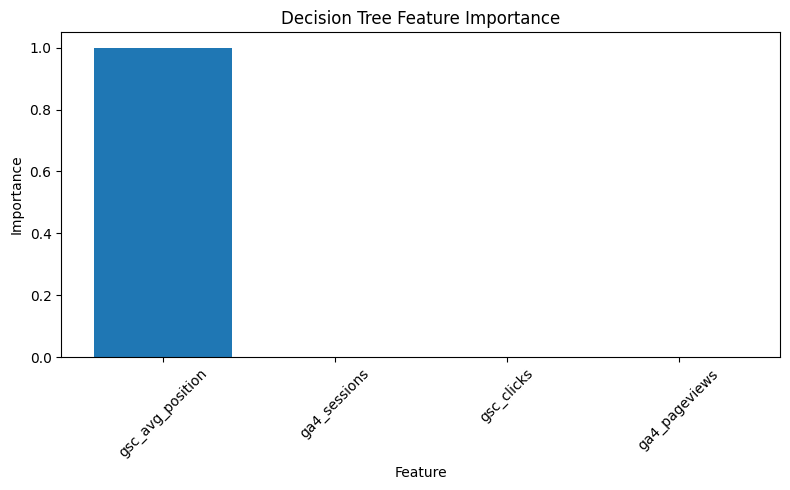

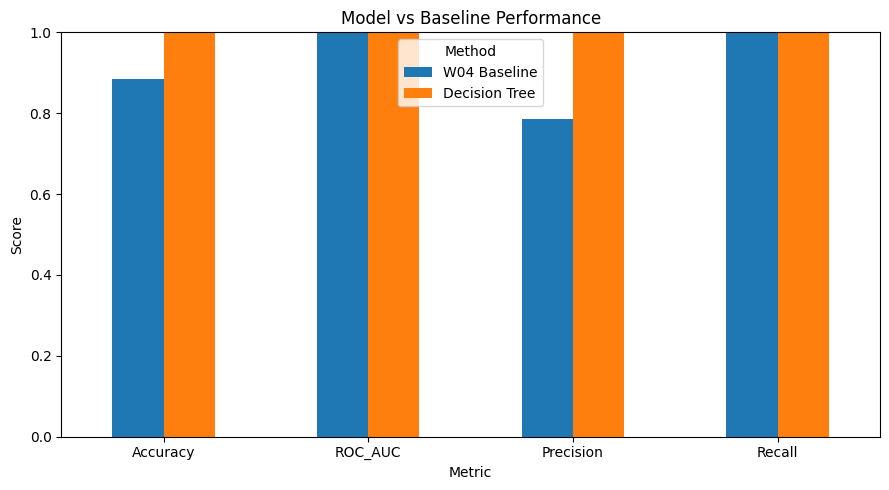


PAPER ARTIFACT CHECK
✓ work/outputs/model_vs_baseline.csv
✓ work/outputs/model_vs_baseline.png
✓ work/outputs/feature_importance.csv
✓ work/outputs/feature_importance.png
✓ work/outputs/action_playbook_queue.csv


In [24]:
import os
import matplotlib.pyplot as plt

os.makedirs("work/outputs", exist_ok=True)

comparison.to_csv(
    "work/outputs/model_vs_baseline.csv",
    index=False
)

importance = pd.DataFrame({
    "feature": model_features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

importance.to_csv(
    "work/outputs/feature_importance.csv",
    index=False
)

plt.figure(figsize=(8, 5))
plt.bar(importance["feature"], importance["importance"])
plt.title("Decision Tree Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("work/outputs/feature_importance.png", dpi=200)
plt.show()

metrics = ["Accuracy", "ROC_AUC", "Precision", "Recall"]

comparison.set_index("Method")[metrics].T.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model vs Baseline Performance")
plt.ylabel("Score")
plt.xlabel("Metric")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("work/outputs/model_vs_baseline.png", dpi=200)
plt.show()

queue_export = queue[
    [
        "content_hash_id",
        "gsc_impressions",
        "gsc_clicks",
        "gsc_avg_position",
        "priority_score",
        "reason_code",
        "action_label"
    ]
].copy()

queue_export = queue_export.head(1000)

queue_export.to_csv(
    "work/outputs/action_playbook_queue.csv",
    index=False
)

artifacts = [
    "work/outputs/model_vs_baseline.csv",
    "work/outputs/model_vs_baseline.png",
    "work/outputs/feature_importance.csv",
    "work/outputs/feature_importance.png",
    "work/outputs/action_playbook_queue.csv"
]

print("\nPAPER ARTIFACT CHECK")

for artifact in artifacts:
    print(
        "✓" if os.path.exists(artifact) else "✗",
        artifact
    )
